# M304 - Scripts optimizados para IA

> Módulo III - Python para la inteligencia artificial
>
> Tema 3: Implementación de scripts optimizados para IA

Contenido:

1. Reporte continuo (curva cuantil/percentil)
2. Reporte discreto (soportes y proporciones)
3. Reporte discretizado (razonamiento)
4. Reporte cruzado (inferencia a la respuesta)

Objetivo: Ensamblar un cubo de datos discretizado

In [1]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

## 1. Reporte continuo (curva cuantil/percentil)

Discretización de las variables continuas

In [2]:
titanic = pandas.read_csv("./conjuntos/titanic.csv")

c1 = titanic["Survived"].map({ # discreta {no, yes}
    0: "no",
    1: "yes"
})
c2 = titanic["Sex"] # discreta {male, famale}
c3 = titanic["Pclass"].map({ # discreta {1st, 2nd, 3rd}
    1: "1st",
    2: "2nd",
    3: "3rd",
})
c4 = titanic["Fare"] # continua
c5 = (~(titanic["Cabin"].isna())).map({ # discreta {no, yes}
    False: "no",
    True: "yes"
})
c6 = titanic["Embarked"].map({ # discreta {southampton, cherbug, queenstown}
    "S": "southampton",
    "C": "cherburg",
    "Q": "queenstown",
})
c7 = titanic["Age"] # continua
c8 = titanic["SibSp"] # continua
c9 = titanic["Parch"] # continua

In [3]:
# Bin-cuantil, Cuartiles, Quintiles, Deciles, Dos-Deciles, Percentiles

c4_q2 = pandas.qcut(c4, q=2) # Q2 (partición por la mediana - 50%)
c4_q2.name = "Fare P2"
c4_q4 = pandas.qcut(c4, q=4) # Q1, Q2, Q3 (partición por cuartiles - 25%)
c4_q4.name = "Fare P4"
c4_q5 = pandas.qcut(c4, q=5) # K1, K2, K3, K4 (partición por quintiles - 20%)
c4_q5.name = "Fare P5"
c4_q10 = pandas.qcut(c4, q=10) # D1, D2, D3, D4, ..., D9 (partición por deciles - 10%)
c4_q10.name = "Fare P10"
c4_q20 = pandas.qcut(c4, q=20) # V1, V2, V3, V4, ..., V19 (partición por dos-deciles - 5%)
c4_q20.name = "Fare P20"

In [4]:
def median(serie):
    return serie.quantile(0.50)
    
def q1(serie):
    return serie.quantile(0.25)
def q2(serie):
    return serie.quantile(0.50)
def q3(serie):
    return serie.quantile(0.75)

def k1(serie):
    return serie.quantile(0.20)
def k2(serie):
    return serie.quantile(0.40)
def k3(serie):
    return serie.quantile(0.60)
def k4(serie):
    return serie.quantile(0.80)

def d1(serie):
    return serie.quantile(0.10)
def d2(serie):
    return serie.quantile(0.20)
def d3(serie):
    return serie.quantile(0.30)
def d4(serie):
    return serie.quantile(0.40)
def d5(serie):
    return serie.quantile(0.50)
def d6(serie):
    return serie.quantile(0.60)
def d7(serie):
    return serie.quantile(0.70)
def d8(serie):
    return serie.quantile(0.80)
def d9(serie):
    return serie.quantile(0.90)

def v1(serie):
    return serie.quantile(0.05)
def v2(serie):
    return serie.quantile(0.10)
def v3(serie):
    return serie.quantile(0.15)
def v4(serie):
    return serie.quantile(0.20)
def v5(serie):
    return serie.quantile(0.25)
def v6(serie):
    return serie.quantile(0.30)
def v7(serie):
    return serie.quantile(0.35)
def v8(serie):
    return serie.quantile(0.40)
def v9(serie):
    return serie.quantile(0.45)
def v10(serie):
    return serie.quantile(0.50)
def v11(serie):
    return serie.quantile(0.55)
def v12(serie):
    return serie.quantile(0.60)
def v13(serie):
    return serie.quantile(0.65)
def v14(serie):
    return serie.quantile(0.70)
def v15(serie):
    return serie.quantile(0.75)
def v16(serie):
    return serie.quantile(0.80)
def v17(serie):
    return serie.quantile(0.85)
def v18(serie):
    return serie.quantile(0.90)
def v19(serie):
    return serie.quantile(0.95)

In [5]:
pandas.DataFrame([c4_q2, c4]).T.groupby("Fare P2").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2) # BAJA / ALTA

Fare                                              
                   count       sum   mean    std    min median     max
Fare P2                                                               
(-0.001, 14.454]   447.0   3895.10   8.71   2.66   0.00   7.92   14.45
(14.454, 512.329]  444.0  24798.85  55.85  61.94  14.46  31.14  512.33

In [6]:
pandas.DataFrame([c4_q4, c4]).T.groupby("Fare P4").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2) # BAJA / MEDIA-BAJA / MEDIA-ALTA / ALTA

Fare                                              
                 count       sum   mean    std    min median     max
Fare P4                                                             
(-0.001, 7.91]   223.0   1568.62   7.03   1.95   0.00   7.75    7.90
(7.91, 14.454]   224.0   2326.48  10.39   2.19   7.92   9.84   14.45
(14.454, 31.0]   222.0   5112.37  23.03   5.09  14.46  25.47   31.00
(31.0, 512.329]  222.0  19686.49  88.68  74.16  31.28  69.55  512.33

In [7]:
pandas.DataFrame([c4_q5, c4]).T.groupby("Fare P5").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2) # BAJA / CENTAL-BAJA / CENTRAL / CENTRAL-ALTA / ALTA

Fare                                               
                   count       sum    mean    std    min median     max
Fare P5                                                                
(-0.001, 7.854]    179.0   1221.30    6.82   2.12   0.00   7.55    7.85
(7.854, 10.5]      184.0   1586.82    8.62   0.94   7.88   8.05   10.50
(10.5, 21.679]     172.0   2616.98   15.22   2.85  10.52  14.46   21.68
(21.679, 39.688]   180.0   5206.07   28.92   4.47  22.02  27.72   39.69
(39.688, 512.329]  176.0  18062.78  102.63  77.45  40.12  77.96  512.33

In [8]:
pandas.DataFrame([c4_q10, c4]).T.groupby("Fare P10").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2) # 1 / 2 / 3 / 4 / 5 / 6 / 7 / 8 / 9 / 10

Fare                                                
                   count       sum    mean    std    min  median     max
Fare P10                                                                
(-0.001, 7.55]      92.0    545.44    5.93   2.67   0.00    7.22    7.55
(7.55, 7.854]       87.0    675.86    7.77   0.05   7.63    7.75    7.85
(7.854, 8.05]      106.0    844.15    7.96   0.07   7.88    7.92    8.05
(8.05, 10.5]        78.0    742.67    9.52   0.82   8.11    9.50   10.50
(10.5, 14.454]      84.0   1086.98   12.94   0.85  10.52   13.00   14.45
(14.454, 21.679]    88.0   1530.00   17.39   2.35  14.46   16.10   21.68
(21.679, 27.0]      89.0   2268.39   25.49   1.26  22.02   26.00   27.00
(27.0, 39.688]      91.0   2937.68   32.28   3.90  27.72   31.28   39.69
(39.688, 77.958]    89.0   5290.57   59.44  10.58  40.12   56.50   77.96
(77.958, 512.329]   87.0  12772.22  146.81  90.48  78.27  113.28  512.33

In [9]:
pandas.DataFrame([c4_q20, c4]).T.groupby("Fare P20").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2) # 1 / 1b / 2 / 2b / 3 / 3b / ... / 9 / 9b / 10

Fare                                                
                   count      sum    mean    std     min  median     max
Fare P20                                                                
(-0.001, 7.225]     55.0   275.23    5.00   3.14    0.00    6.98    7.22
(7.225, 7.55]       37.0   270.21    7.30   0.12    7.23    7.25    7.55
(7.55, 7.75]        48.0   371.33    7.74   0.03    7.63    7.75    7.75
(7.75, 7.854]       39.0   304.53    7.81   0.04    7.78    7.80    7.85
(7.854, 7.91]       44.0   347.32    7.89   0.01    7.88    7.90    7.90
(7.91, 8.05]        62.0   496.83    8.01   0.06    7.92    8.05    8.05
(8.05, 9.0]         28.0   240.40    8.59   0.22    8.11    8.66    9.00
(9.0, 10.5]         50.0   502.27   10.05   0.50    9.22   10.46   10.50
(10.5, 13.0]        65.0   819.96   12.61   0.65   10.52   13.00   13.00
(13.0, 14.454]      19.0   267.02   14.05   0.42   13.42   14.11   14.45
(14.454, 16.1]      47.0   724.18   15.41   0.58   14.46   15.50   16.10
(16.1, 21.679]      41.0   805.82   19.65   1.33   16.70   19.97   21.68
(21.679, 26.0]      61.0  1527.10   25.03   1.28   22.02   26.00   26.00
(26.0, 27.0]        28.0   741.28   26.47   0.20   26.25   26.55   27.00
(27.0, 31.0]        45.0  1313.97   29.20   1.16   27.72   29.12   31.00
(31.0, 39.688]      46.0  1623.70   35.30   3.20   31.28   34.83   39.69
(39.688, 56.496]    47.0  2399.85   51.06   4.50   40.12   52.00   56.50
(56.496, 77.958]    42.0  2890.72   68.83   6.85   56.93   69.55   77.96
(77.958, 112.079]   42.0  3733.66   88.90  10.98   78.27   84.99  110.88
(112.079, 512.329]  45.0  9038.56  200.86  98.50  113.28  153.46  512.33

In [10]:
pandas.DataFrame([c4_q10, c4]).T.groupby("Fare P10").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2)[("Fare", "mean")]

Fare P10
(-0.001, 7.55]         5.93
(7.55, 7.854]          7.77
(7.854, 8.05]          7.96
(8.05, 10.5]           9.52
(10.5, 14.454]        12.94
(14.454, 21.679]      17.39
(21.679, 27.0]        25.49
(27.0, 39.688]        32.28
(39.688, 77.958]      59.44
(77.958, 512.329]    146.81
Name: (Fare, mean), dtype: float64

<Axes: >

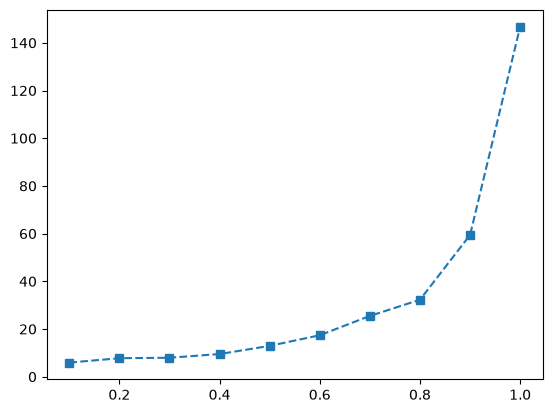

In [11]:
pandas.Series(
    pandas.DataFrame([c4_q10, c4]).T.groupby("Fare P10").agg({
        "Fare": (
            "count",
            "sum",
            "mean",
            "std",
            "min",
            median,
            "max",
        )
    }).astype(float).round(2)[("Fare", "mean")].values,
    index=numpy.linspace(0.1, 1, 10)
).plot.line(marker="s", linestyle="--")

In [12]:
pandas.DataFrame([c4_q20, c4]).T.groupby("Fare P20").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2)[("Fare", "mean")]

Fare P20
(-0.001, 7.225]         5.00
(7.225, 7.55]           7.30
(7.55, 7.75]            7.74
(7.75, 7.854]           7.81
(7.854, 7.91]           7.89
(7.91, 8.05]            8.01
(8.05, 9.0]             8.59
(9.0, 10.5]            10.05
(10.5, 13.0]           12.61
(13.0, 14.454]         14.05
(14.454, 16.1]         15.41
(16.1, 21.679]         19.65
(21.679, 26.0]         25.03
(26.0, 27.0]           26.47
(27.0, 31.0]           29.20
(31.0, 39.688]         35.30
(39.688, 56.496]       51.06
(56.496, 77.958]       68.83
(77.958, 112.079]      88.90
(112.079, 512.329]    200.86
Name: (Fare, mean), dtype: float64

<Axes: >

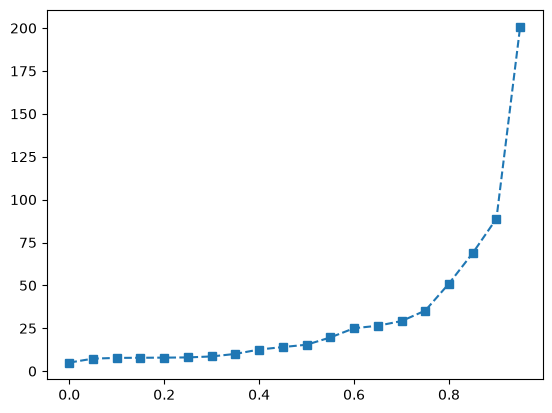

In [13]:
pandas.Series(
    pandas.DataFrame([c4_q20, c4]).T.groupby("Fare P20").agg({
        "Fare": (
            "count",
            "sum",
            "mean",
            "std",
            "min",
            median,
            "max",
        )
    }).astype(float).round(2)[("Fare", "mean")].values,
    index=numpy.linspace(0, 1 - 1/20, 20)
).plot.line(marker="s", linestyle="--")

80% de las tarifas se mantien entre 0 y 32 libras

20% de las tarifas alcanzan hasta 512 libras

In [14]:
def discretizar_tarifas(tarifa):
    if tarifa > c4.quantile(0.9):
        return "E"
    elif tarifa > c4.quantile(0.8):
        return "D"
    elif tarifa > c4.quantile(0.6):
        return "C"
    elif tarifa > c4.quantile(0.4):
        return "B"
    else:
        return "A"

c4.apply(discretizar_tarifas)

0      A
1      D
2      A
3      D
4      A
      ..
886    B
887    C
888    C
889    C
890    A
Name: Fare, Length: 891, dtype: str

<Axes: ylabel='Fare'>

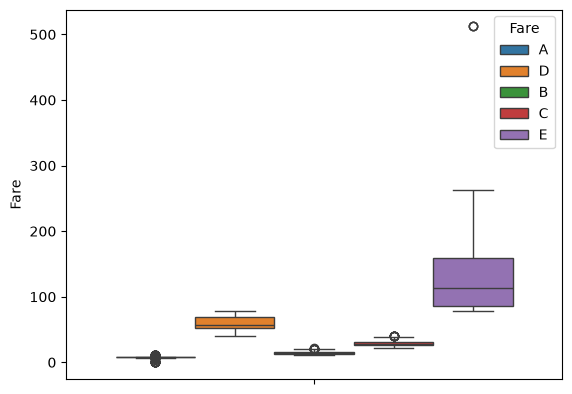

In [15]:
seaborn.boxplot(y=c4, hue=c4.apply(discretizar_tarifas))

In [16]:
cuantiles = pandas.DataFrame([c4_q10, c4]).T.groupby("Fare P10").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2)[("Fare", "mean")]

cuantiles

Fare P10
(-0.001, 7.55]         5.93
(7.55, 7.854]          7.77
(7.854, 8.05]          7.96
(8.05, 10.5]           9.52
(10.5, 14.454]        12.94
(14.454, 21.679]      17.39
(21.679, 27.0]        25.49
(27.0, 39.688]        32.28
(39.688, 77.958]      59.44
(77.958, 512.329]    146.81
Name: (Fare, mean), dtype: float64

In [17]:
cuantiles.rolling(2).first()

Fare P10
(-0.001, 7.55]         NaN
(7.55, 7.854]         5.93
(7.854, 8.05]         7.77
(8.05, 10.5]          7.96
(10.5, 14.454]        9.52
(14.454, 21.679]     12.94
(21.679, 27.0]       17.39
(27.0, 39.688]       25.49
(39.688, 77.958]     32.28
(77.958, 512.329]    59.44
Name: (Fare, mean), dtype: float64

In [18]:
cuantiles - cuantiles.rolling(2).first()

Fare P10
(-0.001, 7.55]         NaN
(7.55, 7.854]         1.84
(7.854, 8.05]         0.19
(8.05, 10.5]          1.56
(10.5, 14.454]        3.42
(14.454, 21.679]      4.45
(21.679, 27.0]        8.10
(27.0, 39.688]        6.79
(39.688, 77.958]     27.16
(77.958, 512.329]    87.37
Name: (Fare, mean), dtype: float64

In [19]:
diferencia_absoluta = cuantiles - cuantiles.rolling(2).first()
diferencia_absoluta.name = "inc abs"
diferencia_relativa = diferencia_absoluta / cuantiles.rolling(2).first()
diferencia_relativa.name = "% inc rel"

print(diferencia_relativa.quantile(0.5))

cambio_relativo = (diferencia_relativa > diferencia_relativa.quantile(0.5))
cambio_relativo.name = "change"

porcentajes_inf = pandas.Series(numpy.linspace(0, 0.9, 10), index=cuantiles.index) * 100
porcentajes_inf .name = "% inf"

porcentajes_sup = pandas.Series(numpy.linspace(0.1, 1, 10), index=cuantiles.index) * 100
porcentajes_sup .name = "% sup"

pandas.DataFrame([porcentajes_inf, porcentajes_sup, cuantiles, 
                  diferencia_absoluta, diferencia_relativa * 100, cambio_relativo]).T

0.3438948995363216


,% inf,% sup,"(Fare, mean)",inc abs,% inc rel,change
Fare P10,,,,,,
"(-0.001, 7.55]",0.0,10.0,5.93,NaN,NaN,0.0
"(7.55, 7.854]",10.0,20.0,7.77,1.84,31.028668,0.0
"(7.854, 8.05]",20.0,30.0,7.96,0.19,2.445302,0.0
"(8.05, 10.5]",30.0,40.0,9.52,1.56,19.597990,0.0
"(10.5, 14.454]",40.0,50.0,12.94,3.42,35.924370,1.0
"(14.454, 21.679]",50.0,60.0,17.39,4.45,34.389490,0.0
"(21.679, 27.0]",60.0,70.0,25.49,8.10,46.578493,1.0
"(27.0, 39.688]",70.0,80.0,32.28,6.79,26.637897,0.0
"(39.688, 77.958]",80.0,90.0,59.44,27.16,84.138786,1.0


In [25]:
from lib1 import quantiles

quantiles(c4, n = 20)

,clu,% inf,% sup,"(Value, mean)",inc abs,% inc rel,change
Quantile,,,,,,,
"(-0.001, 7.225]",1.0,0.0,5.0,5.00,NaN,NaN,0.0
"(7.225, 7.55]",2.0,5.0,10.0,7.30,2.30,46.00,1.0
"(7.55, 7.75]",3.0,10.0,15.0,7.74,0.44,6.03,0.0
"(7.75, 7.854]",4.0,15.0,20.0,7.81,0.07,0.90,0.0
"(7.854, 7.91]",5.0,20.0,25.0,7.89,0.08,1.02,0.0
"(7.91, 8.05]",6.0,25.0,30.0,8.01,0.12,1.52,0.0
"(8.05, 9.0]",7.0,30.0,35.0,8.59,0.58,7.24,0.0
"(9.0, 10.5]",8.0,35.0,40.0,10.05,1.46,17.00,0.0
"(10.5, 13.0]",9.0,40.0,45.0,12.61,2.56,25.47,1.0


In [41]:
quantiles(c7, n = 20, u=0.50)

,clu,% inf,% sup,"(Value, mean)",inc abs,% inc rel,change
Quantile,,,,,,,
"(0.419, 4.0]",1.0,0.0,5.0,2.25,NaN,NaN,0.0
"(4.0, 14.0]",2.0,5.0,10.0,9.43,7.18,319.11,1.0
"(14.0, 17.0]",3.0,10.0,15.0,16.18,6.75,71.58,1.0
"(17.0, 19.0]",4.0,15.0,20.0,18.49,2.31,14.28,1.0
"(19.0, 20.125]",5.0,20.0,25.0,20.00,1.51,8.17,1.0
"(20.125, 22.0]",6.0,25.0,30.0,21.51,1.51,7.55,0.0
"(22.0, 24.0]",7.0,30.0,35.0,23.66,2.15,10.00,1.0
"(24.0, 25.0]",8.0,35.0,40.0,24.98,1.32,5.58,0.0
"(25.0, 27.0]",9.0,40.0,45.0,26.50,1.52,6.08,0.0


In [22]:
quantiles(c7, n = 5, u=0.75)

,clu,% inf,% sup,"(Value, mean)",inc abs,% inc rel,change
Quantile,,,,,,,
"(0.419, 19.0]",1.0,0.0,20.0,11.98,NaN,NaN,0.0
"(19.0, 25.0]",2.0,20.0,40.0,22.68,10.70,89.32,1.0
"(25.0, 31.8]",3.0,40.0,60.0,28.57,5.89,25.97,0.0
"(31.8, 41.0]",4.0,60.0,80.0,35.92,7.35,25.73,0.0
"(41.0, 80.0]",5.0,80.0,100.0,51.64,15.72,43.76,0.0


## 2. Reporte discreto (soportes y proporciones)

In [63]:
x1 = c1
x2 = c2
x3 = c3
x4 = c5
x5 = c6
x6 = pandas.qcut(c4, q=[0, 0.1, 0.45, 0.6, 0.65, 0.8, 1], labels=[f"fare-{g}" for g in numpy.arange(1, 7)])
x7 = pandas.qcut(c7, q=[0, 0.15, 0.35, 0.66, 0.8, 1], labels=[f"age-{g}" for g in numpy.arange(1, 6)])
x8 = pandas.cut(c8, bins=[-1, 0.5, 1.5, 2.5, c8.max()], labels=[f"famh-{g}" for g in numpy.arange(0, 4)])
x9 = pandas.cut(c9, bins=[-1, 0.5, 1.5, 2.5, c9.max()], labels=[f"famv-{g}" for g in numpy.arange(0, 4)])

pandas.DataFrame([x1, x2, x3, x4, x5, x6, x7, x8, x9]).T

,Survived,Sex,Pclass,Cabin,Embarked,Fare,Age,SibSp,Parch
0,no,male,3rd,no,southampton,fare-1,age-2,famh-1,famv-0
1,yes,female,1st,yes,cherburg,fare-6,age-4,famh-1,famv-0
2,yes,female,3rd,no,southampton,fare-2,age-3,famh-0,famv-0
3,yes,female,1st,yes,southampton,fare-6,age-4,famh-1,famv-0
4,no,male,3rd,no,southampton,fare-2,age-4,famh-0,famv-0
...,...,...,...,...,...,...,...,...,...
886,no,male,2nd,no,southampton,fare-2,age-3,famh-0,famv-0
887,yes,female,1st,yes,southampton,fare-5,age-2,famh-0,famv-0
888,no,female,3rd,no,southampton,fare-4,NaN,famh-1,famv-2
889,yes,male,1st,yes,cherburg,fare-5,age-3,famh-0,famv-0


## 3. Reporte discretizado (razonamiento)

## 4. Reporte cruzado (inferencia a la respuesta)